In [ ]:
ML Workflow:
Problem Statement
Data collection

In [ ]:
House prediction System Using ML & Streamlite

Business Problem:
A real -estate company wants to build a ml system
that can estimate the expected selling price of house 
based on its characteristics:

Currently property agent may estimate prices
manually based on experience

This can lead to 

-- Incosistance price
--slow property evalution
--subjective decisions
--difficult compairing many properties
--inaccurate initial pricing

Streamlite web app


Project Architecture:

House_price_Data

Data understanding

Data cleaning

EDA Analysis

Feature Engineering

Train Test Split

Data Processing

Numerical(Mean)               Categorical(Mode)
(Missing values)

StandardScaler                   LabelEncoding

            Multiple LinearRegression(Try Diffrent regression algo)

Model Evalution

Best model selection

Save Model.pkl

Stramlite Application

User Enter Data
Price prediction

In [ ]:
Data Engineer
Data Analyst(Data Reading)

ML Engineer --ML Application pkl

DevOps Engineer  --->Deployment


# Data Collection

In [1]:
import pandas as pd
df=pd.read_csv(r"D:\Downloads\House Price Prediction Dataset (1).csv")

In [2]:
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3.0,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3.0,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3.0,1938,Downtown,Good,No,266746
3,4,966,4,2,2.0,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2.0,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3.0,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1.0,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2.0,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2.0,1936,Urban,Excellent,Yes,161119


In [3]:
df.shape

(2000, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Id         2000 non-null   int64  
 1   Area       2000 non-null   int64  
 2   Bedrooms   2000 non-null   int64  
 3   Bathrooms  2000 non-null   int64  
 4   Floors     1998 non-null   float64
 5   YearBuilt  2000 non-null   int64  
 6   Location   1998 non-null   object 
 7   Condition  2000 non-null   object 
 8   Garage     2000 non-null   object 
 9   Price      2000 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 156.4+ KB


In [5]:
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,1998.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.992993,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809280,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


# Quality check

In [7]:
df.isna().sum()

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       2
YearBuilt    0
Location     2
Condition    0
Garage       0
Price        0
dtype: int64

In [8]:
x=df['Floors'].mean()
df['Floors']=df['Floors'].fillna(x)

In [9]:
x

1.992992992992993

In [10]:
x=df['Location'].mode()[0]
df['Location']=df['Location'].fillna(x)

In [15]:
df.isna().sum()

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

In [21]:
df.duplicated().sum()

0

In [23]:
for col in df.columns:
    print(col,df[col].unique()[:10])

Id [ 1  2  3  4  5  6  7  8  9 10]
Area [1360 4272 3592  966 4926 3944 3671 3419  630 2185]
Bedrooms [5 2 4 1 3]
Bathrooms [4 2 1 3]
Floors [3.         2.         1.         1.99299299]
YearBuilt [1970 1958 1938 1902 1975 1906 1948 1925 1932 2000]
Location ['Downtown' 'Suburban' 'Urban' 'Rural']
Condition ['Excellent' 'Good' 'Fair' 'Poor']
Garage ['No' 'Yes']
Price [149919 424998 266746 244020 636056  93262 448722 594893 652878 340375]


In [26]:
df['Price'].describe()

count      2000.000000
mean     537676.855000
std      276428.845719
min       50005.000000
25%      300098.000000
50%      539254.000000
75%      780086.000000
max      999656.000000
Name: Price, dtype: float64

# Remove Unwanted Columns

In [29]:
df=df.drop('Id',axis=1)

In [31]:
df

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1360,5,4,3.0,1970,Downtown,Excellent,No,149919
1,4272,5,4,3.0,1958,Downtown,Excellent,No,424998
2,3592,2,2,3.0,1938,Downtown,Good,No,266746
3,966,4,2,2.0,1902,Suburban,Fair,Yes,244020
4,4926,1,4,2.0,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...
1995,4994,5,4,3.0,1923,Suburban,Poor,No,295620
1996,3046,5,2,1.0,2019,Suburban,Poor,Yes,580929
1997,1062,5,1,2.0,1903,Rural,Poor,No,476925
1998,4062,3,1,2.0,1936,Urban,Excellent,Yes,161119


# EDA

##### Area Vs Price

Text(0.5, 1.0, 'Area Vs House price')

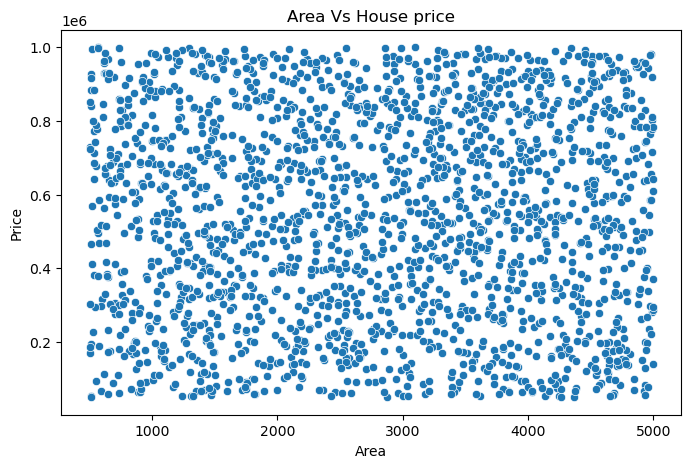

In [35]:
import seaborn as sb
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sb.scatterplot(
    data=df,
    x='Area',
    y='Price'
)

plt.title('Area Vs House price')

# Correlation Analysis

<Axes: >

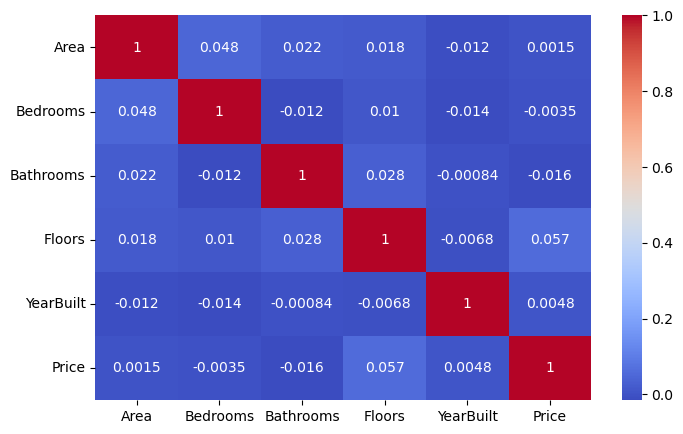

In [37]:
plt.figure(figsize=(8,5))
sb.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

# Categorical Analysis

### Location Vs Price

<Axes: xlabel='Location', ylabel='Price'>

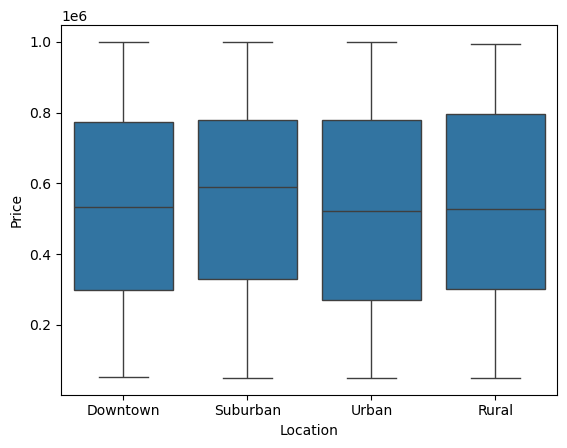

In [40]:
sb.boxplot(data=df,
          x='Location',
          y='Price')

In [41]:
df.columns

Index(['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location',
       'Condition', 'Garage', 'Price'],
      dtype='object')

<Axes: xlabel='Condition', ylabel='Price'>

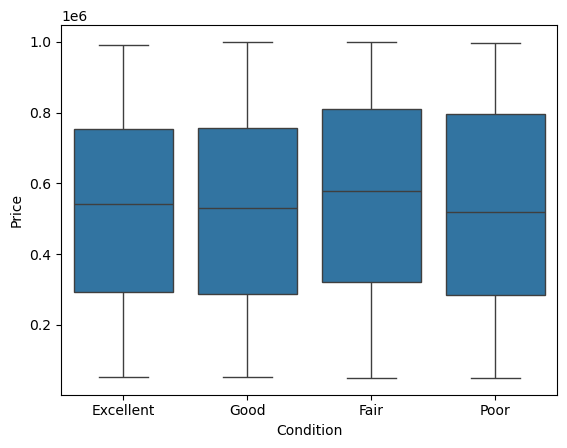

In [42]:
sb.boxplot(
    data=df,
    x='Condition',
    y='Price'
)

<Axes: xlabel='Garage', ylabel='Price'>

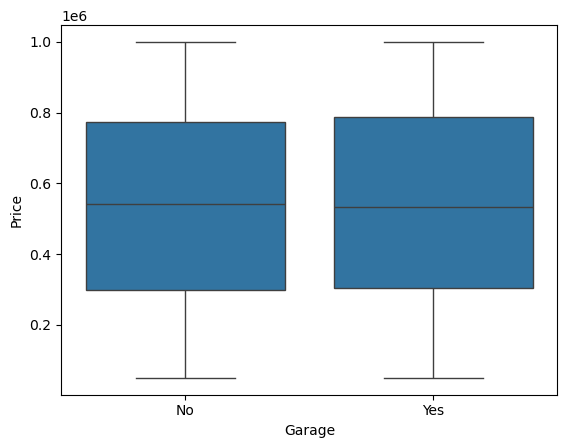

In [43]:
sb.boxplot(
    data=df,
    x='Garage',
    y='Price'
)

# Define Target

In [45]:
Y=df[['Price']]
X=df.drop(labels=['Price'],axis=1)

In [46]:
Y

,Price
0,149919
1,424998
2,266746
3,244020
4,636056
...,...
1995,295620
1996,580929
1997,476925
1998,161119


In [47]:
X

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage
0,1360,5,4,3.0,1970,Downtown,Excellent,No
1,4272,5,4,3.0,1958,Downtown,Excellent,No
2,3592,2,2,3.0,1938,Downtown,Good,No
3,966,4,2,2.0,1902,Suburban,Fair,Yes
4,4926,1,4,2.0,1975,Downtown,Fair,Yes
...,...,...,...,...,...,...,...,...
1995,4994,5,4,3.0,1923,Suburban,Poor,No
1996,3046,5,2,1.0,2019,Suburban,Poor,Yes
1997,1062,5,1,2.0,1903,Rural,Poor,No
1998,4062,3,1,2.0,1936,Urban,Excellent,Yes


# Train test split

In [51]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,test_size=0.2,random_state=21)

In [57]:
# 1600 -->Training
# 400 -->testing

In [59]:
xtrain

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage
1490,1887,1,1,1.0,1909,Rural,Excellent,Yes
965,1811,1,3,3.0,1970,Rural,Poor,No
1216,4569,3,1,1.0,1948,Downtown,Good,Yes
500,1884,4,3,2.0,2005,Downtown,Excellent,Yes
403,3569,1,1,2.0,1997,Downtown,Excellent,Yes
...,...,...,...,...,...,...,...,...
48,534,1,3,2.0,1999,Downtown,Poor,Yes
772,2469,5,3,1.0,1958,Rural,Excellent,No
1848,2690,3,1,1.0,1925,Suburban,Good,No
1231,4635,4,4,2.0,1955,Downtown,Fair,No


In [61]:
xtest

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage
541,3245,1,4,3.0,1959,Urban,Poor,Yes
1211,3237,5,1,2.0,1966,Rural,Poor,Yes
1862,4419,5,3,2.0,1919,Downtown,Excellent,No
1094,3208,5,4,2.0,1905,Rural,Fair,No
465,2042,1,1,2.0,1973,Suburban,Good,No
...,...,...,...,...,...,...,...,...
93,3190,3,2,3.0,1950,Downtown,Excellent,No
985,4094,1,4,3.0,2017,Suburban,Good,No
736,1641,4,2,1.0,1940,Suburban,Fair,Yes
21,3247,4,3,1.0,1931,Downtown,Excellent,No


In [63]:
numeric_features=[]
categorical_feature=[]

for i in X.columns:
    if X[i].dtypes=='object':
        categorical_feature.append(i)
    else:
        numeric_features.append(i)

In [65]:
categorical_feature

['Location', 'Condition', 'Garage']

In [67]:
numeric_features

['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']

In [69]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# numerical_pipeline=Pipeline([
#     ('imputer',SimpleImputer(strategy='mean')),
#     ('scaler',StandardScaler())
#      ])

# categorical_pipeline=Pipeline([
#     ('imputer',SimpleImputer(strategy='most_frequent')),
#     ('encoder',OneHotEncoder(handle_unknown='ignore'))
#      ])

### Combine

In [72]:
# from sklearn.compose import ColumnTransformer
# preprocessor=ColumnTransformer(
#     [
#         ('num',numerical_pipeline,numeric_features),
#         ('cat',categorical_pipeline,categorical_feature)
#     ]
# )

In [74]:
cat_col=df[categorical_feature]

In [76]:
cat_col

,Location,Condition,Garage
0,Downtown,Excellent,No
1,Downtown,Excellent,No
2,Downtown,Good,No
3,Suburban,Fair,Yes
4,Downtown,Fair,Yes
...,...,...,...
1995,Suburban,Poor,No
1996,Suburban,Poor,Yes
1997,Rural,Poor,No
1998,Urban,Excellent,Yes


In [78]:
con_col=df[numeric_features]

In [80]:
con_col

,Area,Bedrooms,Bathrooms,Floors,YearBuilt
0,1360,5,4,3.0,1970
1,4272,5,4,3.0,1958
2,3592,2,2,3.0,1938
3,966,4,2,2.0,1902
4,4926,1,4,2.0,1975
...,...,...,...,...,...
1995,4994,5,4,3.0,1923
1996,3046,5,2,1.0,2019
1997,1062,5,1,2.0,1903
1998,4062,3,1,2.0,1936


In [82]:
ohe=OneHotEncoder(sparse_output=False)
Cat_encode=ohe.fit_transform(cat_col)

In [84]:
Cat_encode

array([[1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 1., 0., ..., 1., 1., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 1., 0.]])

In [86]:
encoded_column=ohe.get_feature_names_out()

In [88]:
encoded_column

array(['Location_Downtown', 'Location_Rural', 'Location_Suburban',
       'Location_Urban', 'Condition_Excellent', 'Condition_Fair',
       'Condition_Good', 'Condition_Poor', 'Garage_No', 'Garage_Yes'],
      dtype=object)

In [90]:
import pandas as pd

ohe_df=pd.DataFrame(Cat_encode,columns=encoded_column)

In [92]:
ohe_df

,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
1995,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1996,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1997,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1998,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [94]:
sc=StandardScaler()

st_col=sc.fit_transform(con_col)

In [96]:
std_colm=sc.get_feature_names_out()

In [98]:
std_df=pd.DataFrame(st_col,columns=std_colm)

In [100]:
std_df

,Area,Bedrooms,Bathrooms,Floors,YearBuilt
0,-1.101471,1.401791,1.305568,1.245260,0.238155
1,1.147485,1.401791,1.305568,1.245260,-0.095942
2,0.622317,-0.704581,-0.498326,1.245260,-0.652770
3,-1.405759,0.699667,-0.498326,0.008665,-1.655061
4,1.652574,-1.406705,1.305568,0.008665,0.377363
...,...,...,...,...,...
1995,1.705091,1.401791,1.305568,1.245260,-1.070391
1996,0.200638,1.401791,-0.498326,-1.227930,1.602385
1997,-1.331618,1.401791,-1.400273,0.008665,-1.627219
1998,0.985301,-0.002457,-1.400273,0.008665,-0.708453


In [102]:
scaled_df=pd.concat([std_df,ohe_df],axis=1)

In [104]:
scaled_df.isna().sum()

Area                   0
Bedrooms               0
Bathrooms              0
Floors                 0
YearBuilt              0
Location_Downtown      0
Location_Rural         0
Location_Suburban      0
Location_Urban         0
Condition_Excellent    0
Condition_Fair         0
Condition_Good         0
Condition_Poor         0
Garage_No              0
Garage_Yes             0
dtype: int64

In [107]:
xtrain,xtest,ytrain,ytest=train_test_split(scaled_df,Y,test_size=0.2,random_state=21)

In [109]:
xtrain

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
1490,-0.694465,-1.406705,-1.400273,-1.227930,-1.460171,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
965,-0.753160,-1.406705,0.403621,1.245260,0.238155,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1216,1.376860,-0.002457,-1.400273,-1.227930,-0.374356,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
500,-0.696782,0.699667,0.403621,0.008665,1.212605,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
403,0.604554,-1.406705,-1.400273,0.008665,0.989874,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48,-1.739396,-1.406705,0.403621,0.008665,1.045557,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
772,-0.244983,1.401791,0.403621,-1.227930,-0.095942,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1848,-0.074303,-0.002457,-1.400273,-1.227930,-1.014708,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1231,1.427833,0.699667,1.305568,0.008665,-0.179466,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [111]:
xtest

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
541,0.354327,-1.406705,1.305568,1.245260,-0.068100,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
1211,0.348148,1.401791,-1.400273,0.008665,0.126790,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1862,1.261014,1.401791,0.403621,0.008665,-1.181757,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1094,0.325751,1.401791,1.305568,0.008665,-1.571537,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
465,-0.574758,-1.406705,-1.400273,0.008665,0.321680,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,0.311850,-0.002457,-0.498326,1.245260,-0.318673,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
985,1.010015,-1.406705,1.305568,1.245260,1.546702,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
736,-0.884453,0.699667,-0.498326,-1.227930,-0.597087,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
21,0.355871,0.699667,0.403621,-1.227930,-0.847660,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [123]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

model_Lr=lr.fit(xtrain,ytrain)


# Prediction

In [126]:
y_pred=model_Lr.predict(xtest)

In [128]:
y_pred

array([[525312.],
       [521216.],
       [527360.],
       [566272.],
       [551936.],
       [543744.],
       [553984.],
       [527360.],
       [537600.],
       [557056.],
       [568320.],
       [548864.],
       [555008.],
       [521216.],
       [517120.],
       [563200.],
       [562176.],
       [501760.],
       [570368.],
       [550400.],
       [521216.],
       [553984.],
       [585728.],
       [519168.],
       [584704.],
       [515584.],
       [537600.],
       [509952.],
       [545792.],
       [553984.],
       [523264.],
       [515072.],
       [542720.],
       [538624.],
       [531456.],
       [494592.],
       [524288.],
       [575488.],
       [510976.],
       [495616.],
       [523264.],
       [545280.],
       [545792.],
       [539648.],
       [558080.],
       [517120.],
       [552960.],
       [558080.],
       [586752.],
       [576000.],
       [506368.],
       [528384.],
       [553472.],
       [547328.],
       [537600.],
       [54

# Model Evalution

In [130]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
mean_absolute_error(ytest,y_pred)

230350.835

In [ ]:
Ridge/Lasso
Tree based




In [406]:
def evalute_model(model,xtrain,xtest,ytrain,ytest):
    model.fit(xtrain,ytrain)
    predictions=model.predict(xtest)

    mae=mean_absolute_error(ytest,predictions)
    mse=mean_squared_error(ytest,predictions)

    return mae,mse

In [408]:
evalute_model(model,xtrain,xtest,ytrain,ytest)

(230350.835, 72170947359.485)

## Pick Best Model

In [133]:
best_model=model_Lr

In [137]:
import joblib
joblib.dump(
    best_model,
    'house_price_model.pkl'
)

['house_price_model.pkl']

In [139]:
pwd

'C:\\Users\\Lenovo'